# Mask Analysis, Morphology & Segmentation Evaluation

This notebook focuses on mask analysis, connected components, morphological operations, hole filling, and segmentation baseline evaluation for the Field-PDD dataset.

**Main objectives:**
- Analyze mask integrity and pixel distribution.
- Perform connected components analysis.
- Apply morphological opening and closing.
- Evaluate hole filling.
- Compare segmentation baseline methods.
- Analyze class-wise performance and failure cases.

In [150]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Image

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Dataset Overview and Mask Integrity

The Field-PDD dataset contains 240 images divided into three disease classes.

The dataset split is:
- Training: 168 images
- Validation: 36 images
- Testing: 36 images

The integrity checks reported no missing files. A total of 125 label-consistency exception pixels were detected across 17 images.

,Pixel Value,Meaning,Percentage
0,0,Background,78.44
1,127,Ignore / Uncertain,17.90
2,255,Foreground,3.66


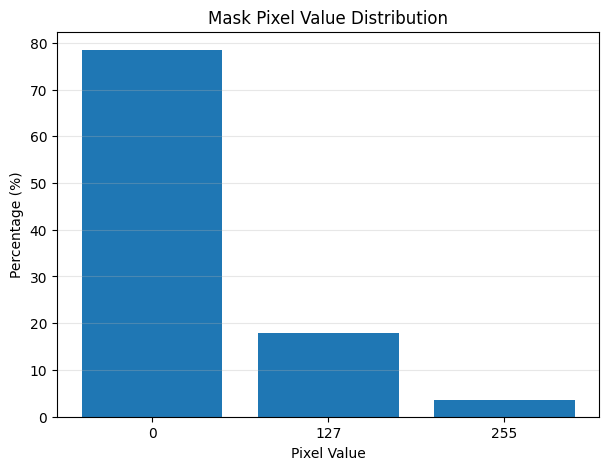

In [152]:
pixel_distribution = pd.DataFrame({
    "Pixel Value": [0, 127, 255],
    "Meaning": ["Background", "Ignore / Uncertain", "Foreground"],
    "Percentage": [78.44, 17.90, 3.66]
})

display(pixel_distribution)

plt.figure(figsize=(7, 5))
plt.bar(
    pixel_distribution["Pixel Value"].astype(str),
    pixel_distribution["Percentage"]
)
plt.xlabel("Pixel Value")
plt.ylabel("Percentage (%)")
plt.title("Mask Pixel Value Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 2. Connected Components Analysis

Connected component analysis identifies separate foreground regions in binary masks.

Only pixels with value 255 are considered foreground, while values 0 and 127 are treated as background.

Eight-connectivity is used to identify connected regions.

The analysis was performed across all 240 masks. The saved visualization represents a single sample.

## 4. Morphological Operations

Morphological operations were applied to binary masks using three kernel sizes:

- 3×3
- 5×5
- 7×7

### Operations
- Opening: Removes small foreground regions.
- Closing: Fills small gaps and connects nearby foreground regions.

The experiments covered 240 masks and generated 1,440 operation records.

IoU measures similarity between the processed mask and the original binary mask. It does not represent independent segmentation accuracy.

,Operation,Kernel Size,IoU
0,Opening,3x3,0.971170
1,Opening,5x5,0.884642
2,Opening,7x7,0.724633
3,Closing,3x3,0.986536
4,Closing,5x5,0.953249
5,Closing,7x7,0.906783


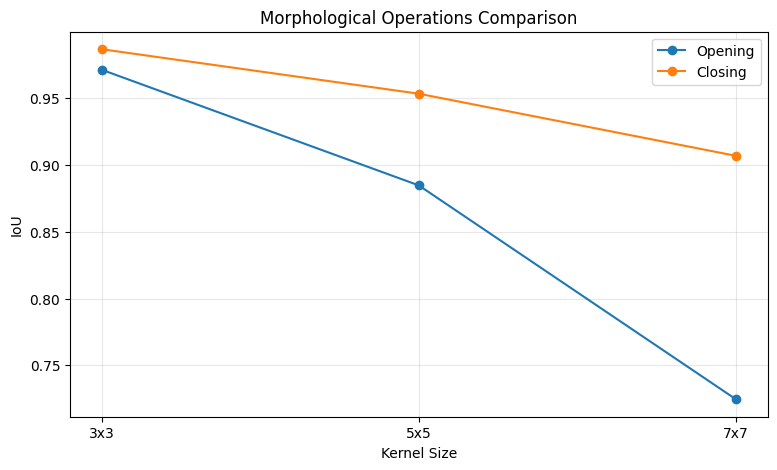

In [155]:
morphology_results = pd.DataFrame({
    "Operation": [
        "Opening", "Opening", "Opening",
        "Closing", "Closing", "Closing"
    ],
    "Kernel Size": ["3x3", "5x5", "7x7", "3x3", "5x5", "7x7"],
    "IoU": [
        0.971170, 0.884642, 0.724633,
        0.986536, 0.953249, 0.906783
    ]
})

display(morphology_results)

plt.figure(figsize=(9, 5))

for operation in morphology_results["Operation"].unique():
    data = morphology_results[
        morphology_results["Operation"] == operation
    ]

    plt.plot(
        data["Kernel Size"],
        data["IoU"],
        marker="o",
        label=operation
    )

plt.xlabel("Kernel Size")
plt.ylabel("IoU")
plt.title("Morphological Operations Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Hole Filling

Hole filling is used to fill enclosed background regions inside foreground objects.

The recorded IoU between the processed and original masks was 0.983655, indicating high mask preservation.

## 6. Segmentation Baseline Evaluation

Three baseline approaches were evaluated on 36 validation images:

- Trivial Mean
- Trivial Median
- Simple Otsu Thresholding

Performance was evaluated using Intersection over Union (IoU).

For this evaluation, ground-truth foreground pixels were defined using values greater than zero.

,Method,Mean IoU,Median IoU
0,Trivial Mean,0.2301,NaN
1,Trivial Median,0.2238,NaN
2,Simple (Otsu),0.3442,0.2476


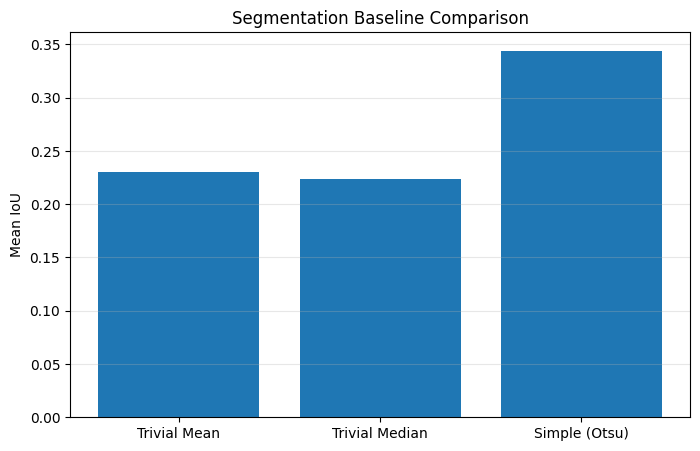

In [156]:
baseline_results = pd.DataFrame({
    "Method": [
        "Trivial Mean",
        "Trivial Median",
        "Simple (Otsu)"
    ],
    "Mean IoU": [0.2301, 0.2238, 0.3442],
    "Median IoU": [np.nan, np.nan, 0.2476]
})

display(baseline_results)

plt.figure(figsize=(8, 5))
plt.bar(
    baseline_results["Method"],
    baseline_results["Mean IoU"]
)

plt.ylabel("Mean IoU")
plt.title("Segmentation Baseline Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 7. Class-wise Evaluation

Segmentation performance varies across the three disease classes.

,Class,Trivial Mean IoU,Simple (Otsu) IoU
0,cedar_apple_rust,0.1699,0.2878
1,soybean_bacterial_blight,0.3085,0.6006
2,wheat_stripe_rust,0.2118,0.1443


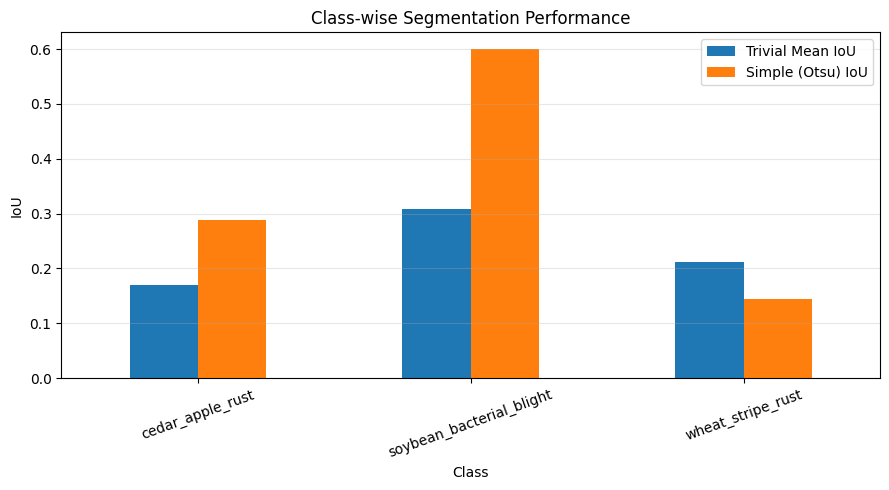

In [157]:
class_results = pd.DataFrame({
    "Class": [
        "cedar_apple_rust",
        "soybean_bacterial_blight",
        "wheat_stripe_rust"
    ],
    "Trivial Mean IoU": [0.1699, 0.3085, 0.2118],
    "Simple (Otsu) IoU": [0.2878, 0.6006, 0.1443]
})

display(class_results)

class_results.set_index("Class").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("IoU")
plt.title("Class-wise Segmentation Performance")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Failure Analysis

The following tables show examples of the lowest and highest segmentation IoU scores.

These examples highlight the variation in segmentation performance between images and disease classes.

In [158]:
worst_samples = pd.DataFrame({
    "Image": [
        "Apple_0331",
        "Wheat_C230514_0059",
        "Wheat_C230514_0050",
        "Wheat_C230514_0056",
        "Wheat_C230514_0048"
    ],
    "Class": [
        "cedar_apple_rust",
        "wheat_stripe_rust",
        "wheat_stripe_rust",
        "wheat_stripe_rust",
        "wheat_stripe_rust"
    ],
    "Trivial Mean IoU": [
        0.057584, 0.074261, 0.076566, 0.101462, 0.144905
    ],
    "Simple (Otsu) IoU": [
        0.064308, 0.079119, 0.082214, 0.091688, 0.107521
    ]
})

best_samples = pd.DataFrame({
    "Image": [
        "Soybean_0055",
        "Soybean_0045",
        "Soybean_0088"
    ],
    "Trivial Mean IoU": [
        0.326476, 0.193888, 0.227678
    ],
    "Simple (Otsu) IoU": [
        0.820740, 0.745871, 0.698588
    ]
})

print("Worst Performing Samples")
display(worst_samples)

print("Best Performing Samples")
display(best_samples)

Worst Performing Samples


,Image,Class,Trivial Mean IoU,Simple (Otsu) IoU
0,Apple_0331,cedar_apple_rust,0.057584,0.064308
1,Wheat_C230514_0059,wheat_stripe_rust,0.074261,0.079119
2,Wheat_C230514_0050,wheat_stripe_rust,0.076566,0.082214
3,Wheat_C230514_0056,wheat_stripe_rust,0.101462,0.091688
4,Wheat_C230514_0048,wheat_stripe_rust,0.144905,0.107521


Best Performing Samples


,Image,Trivial Mean IoU,Simple (Otsu) IoU
0,Soybean_0055,0.326476,0.820740
1,Soybean_0045,0.193888,0.745871
2,Soybean_0088,0.227678,0.698588


## 9. Result Visualizations

The following figures summarize connected components, morphological comparisons, and hole filling results.


connected_components_analysis.png


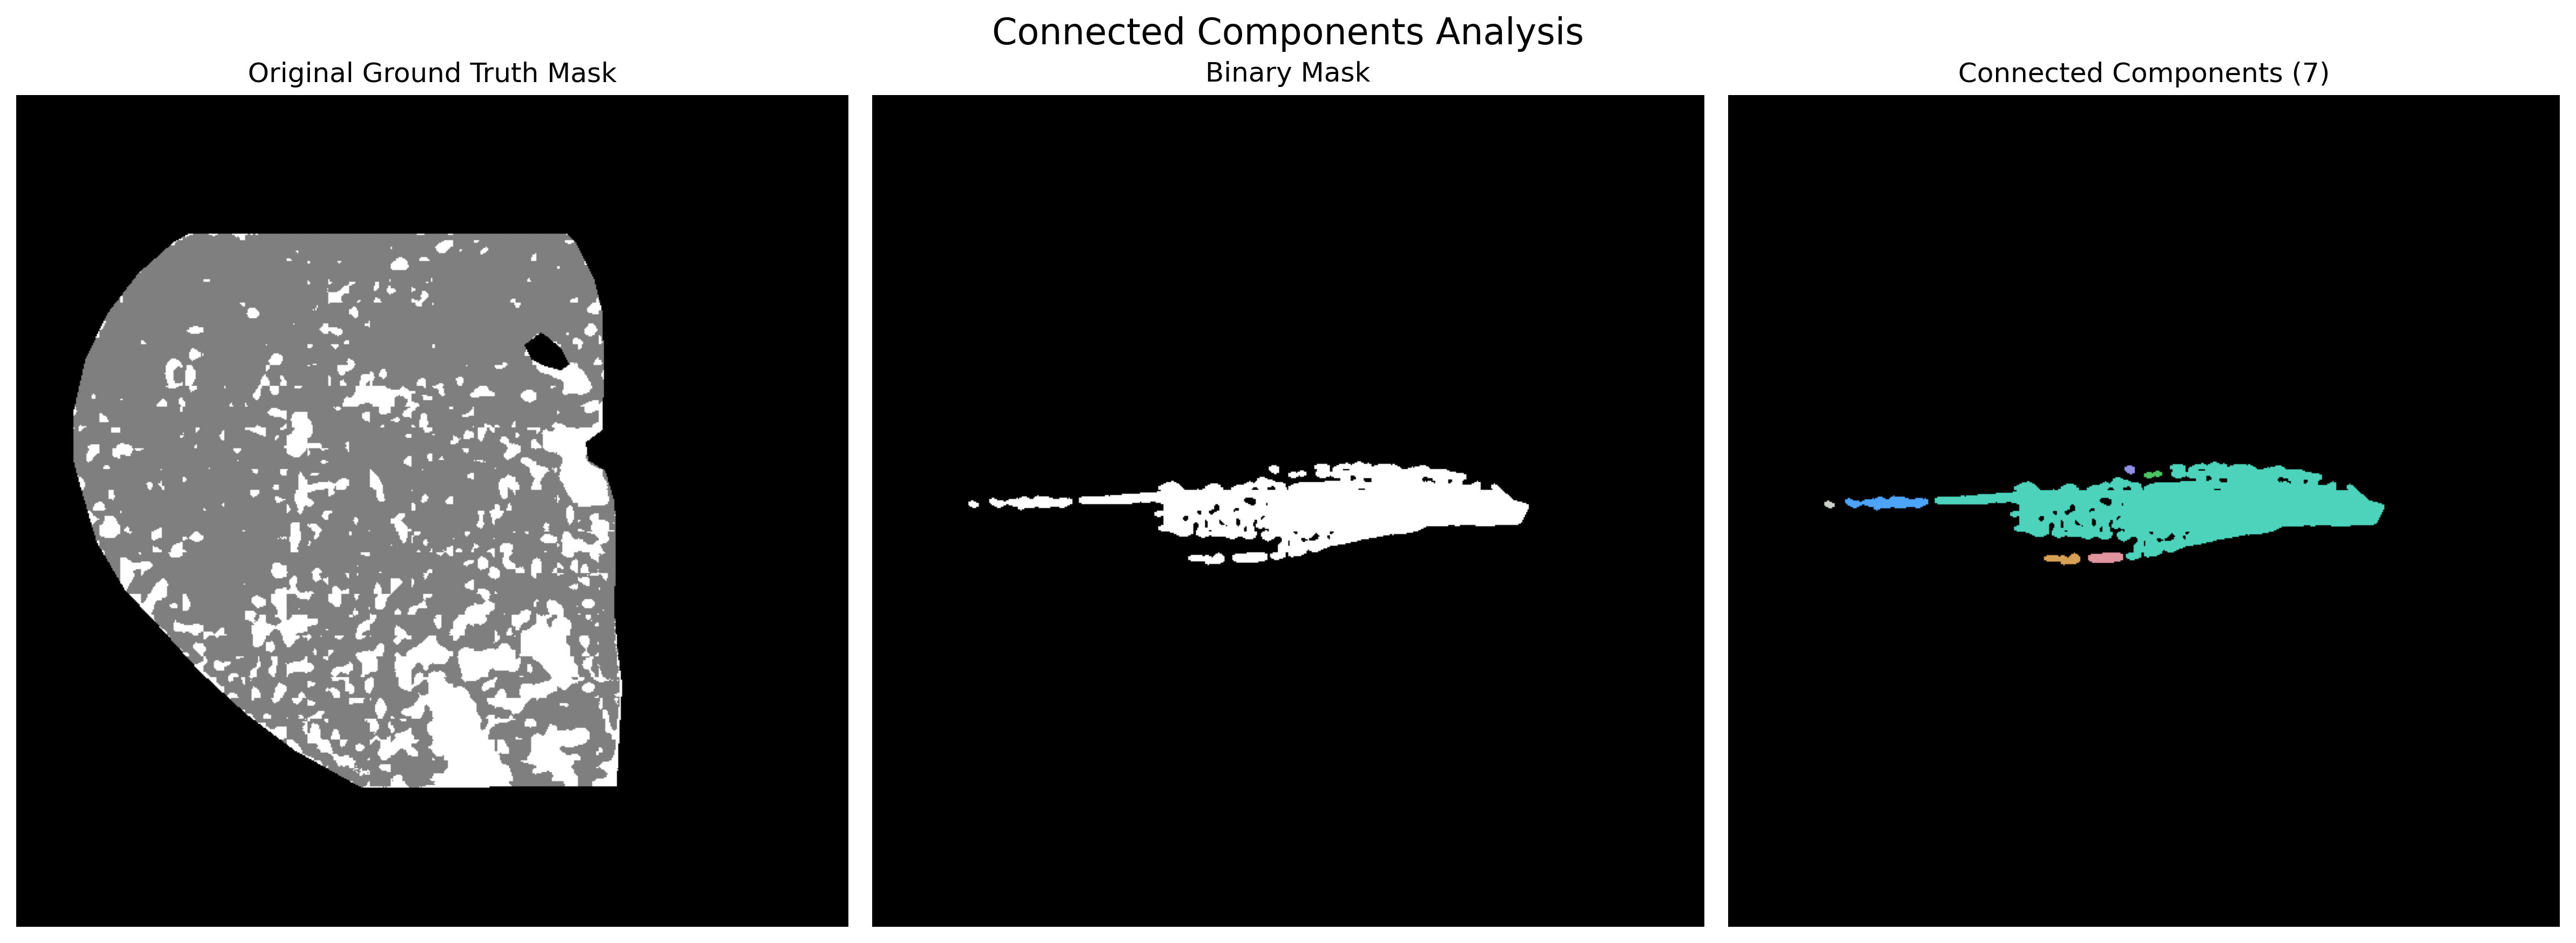


morphology_comparison.png


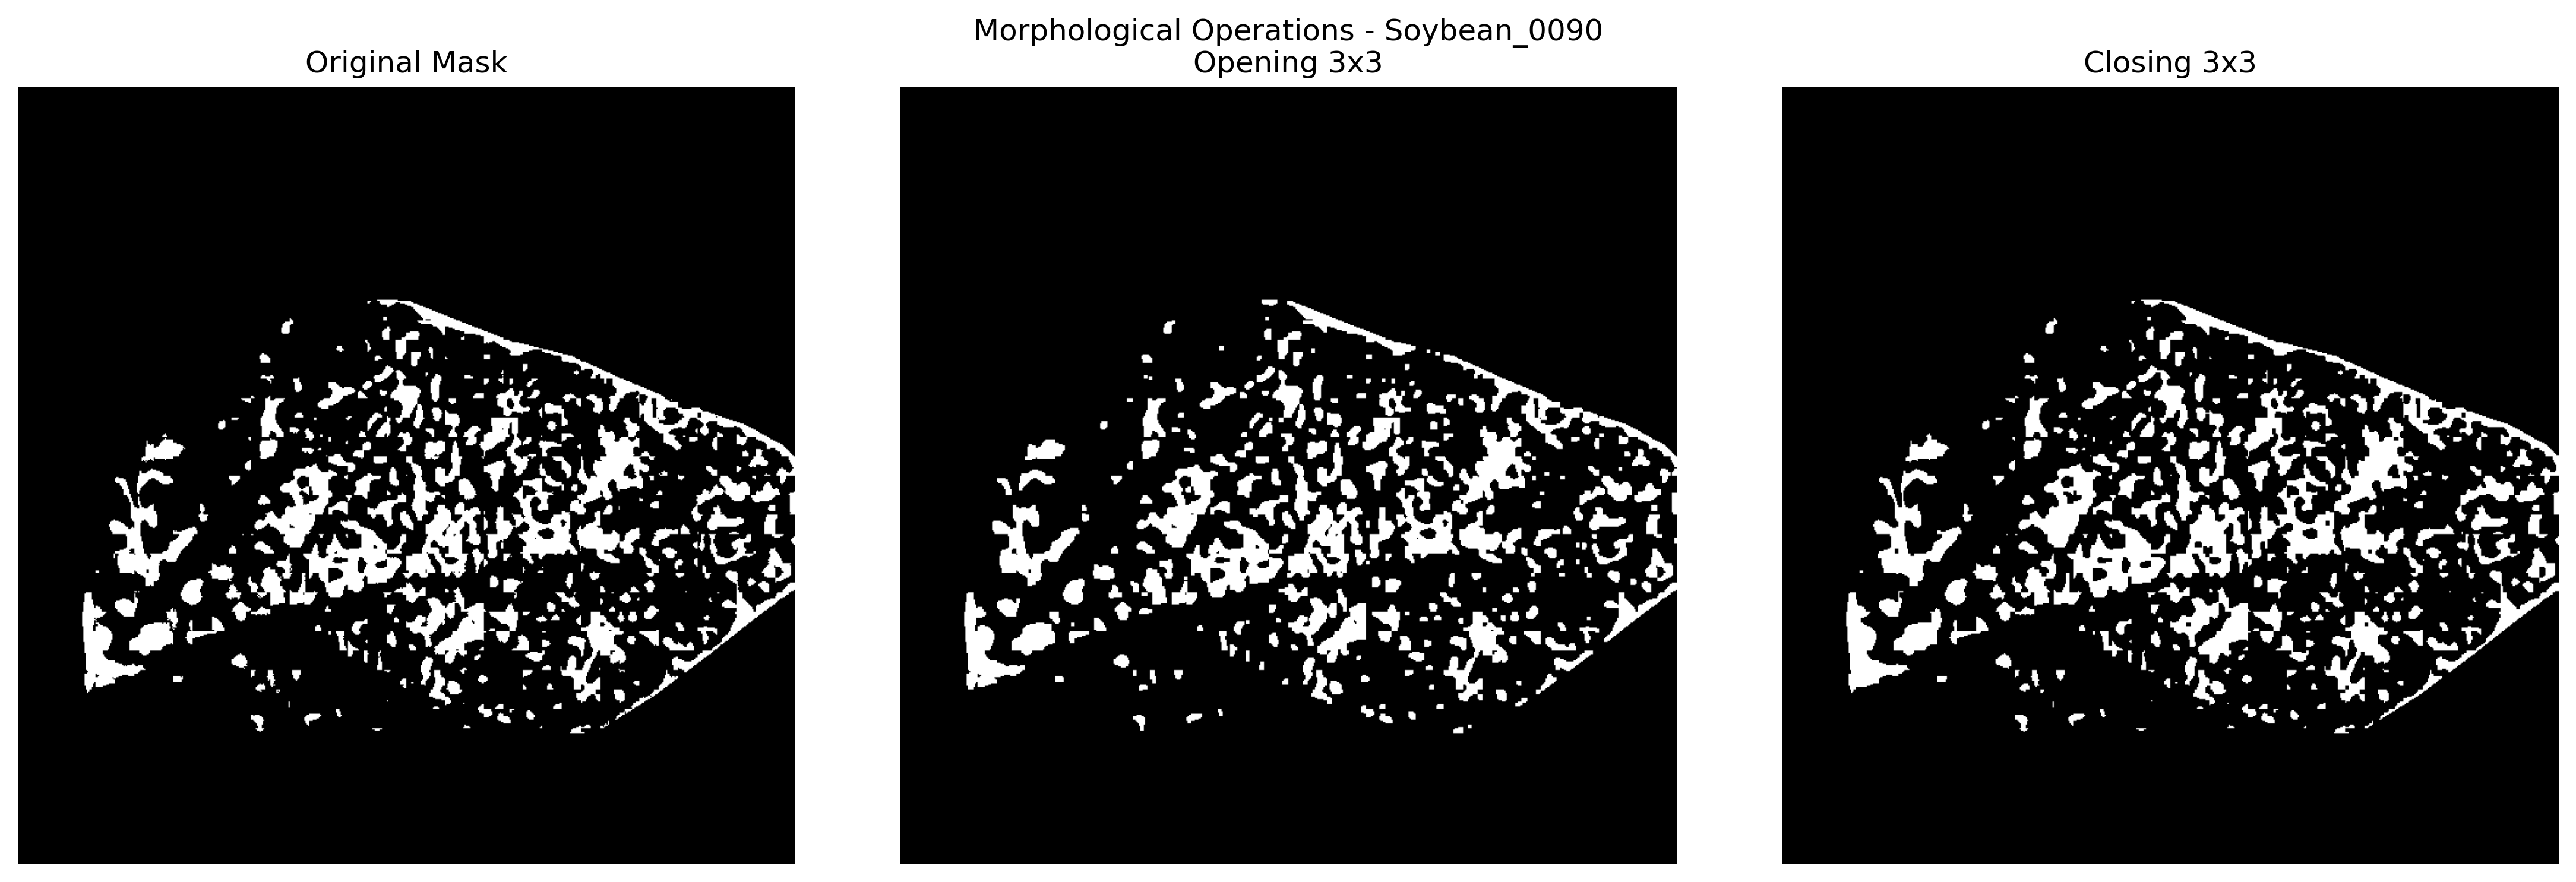


morphology_iou_comparison.png


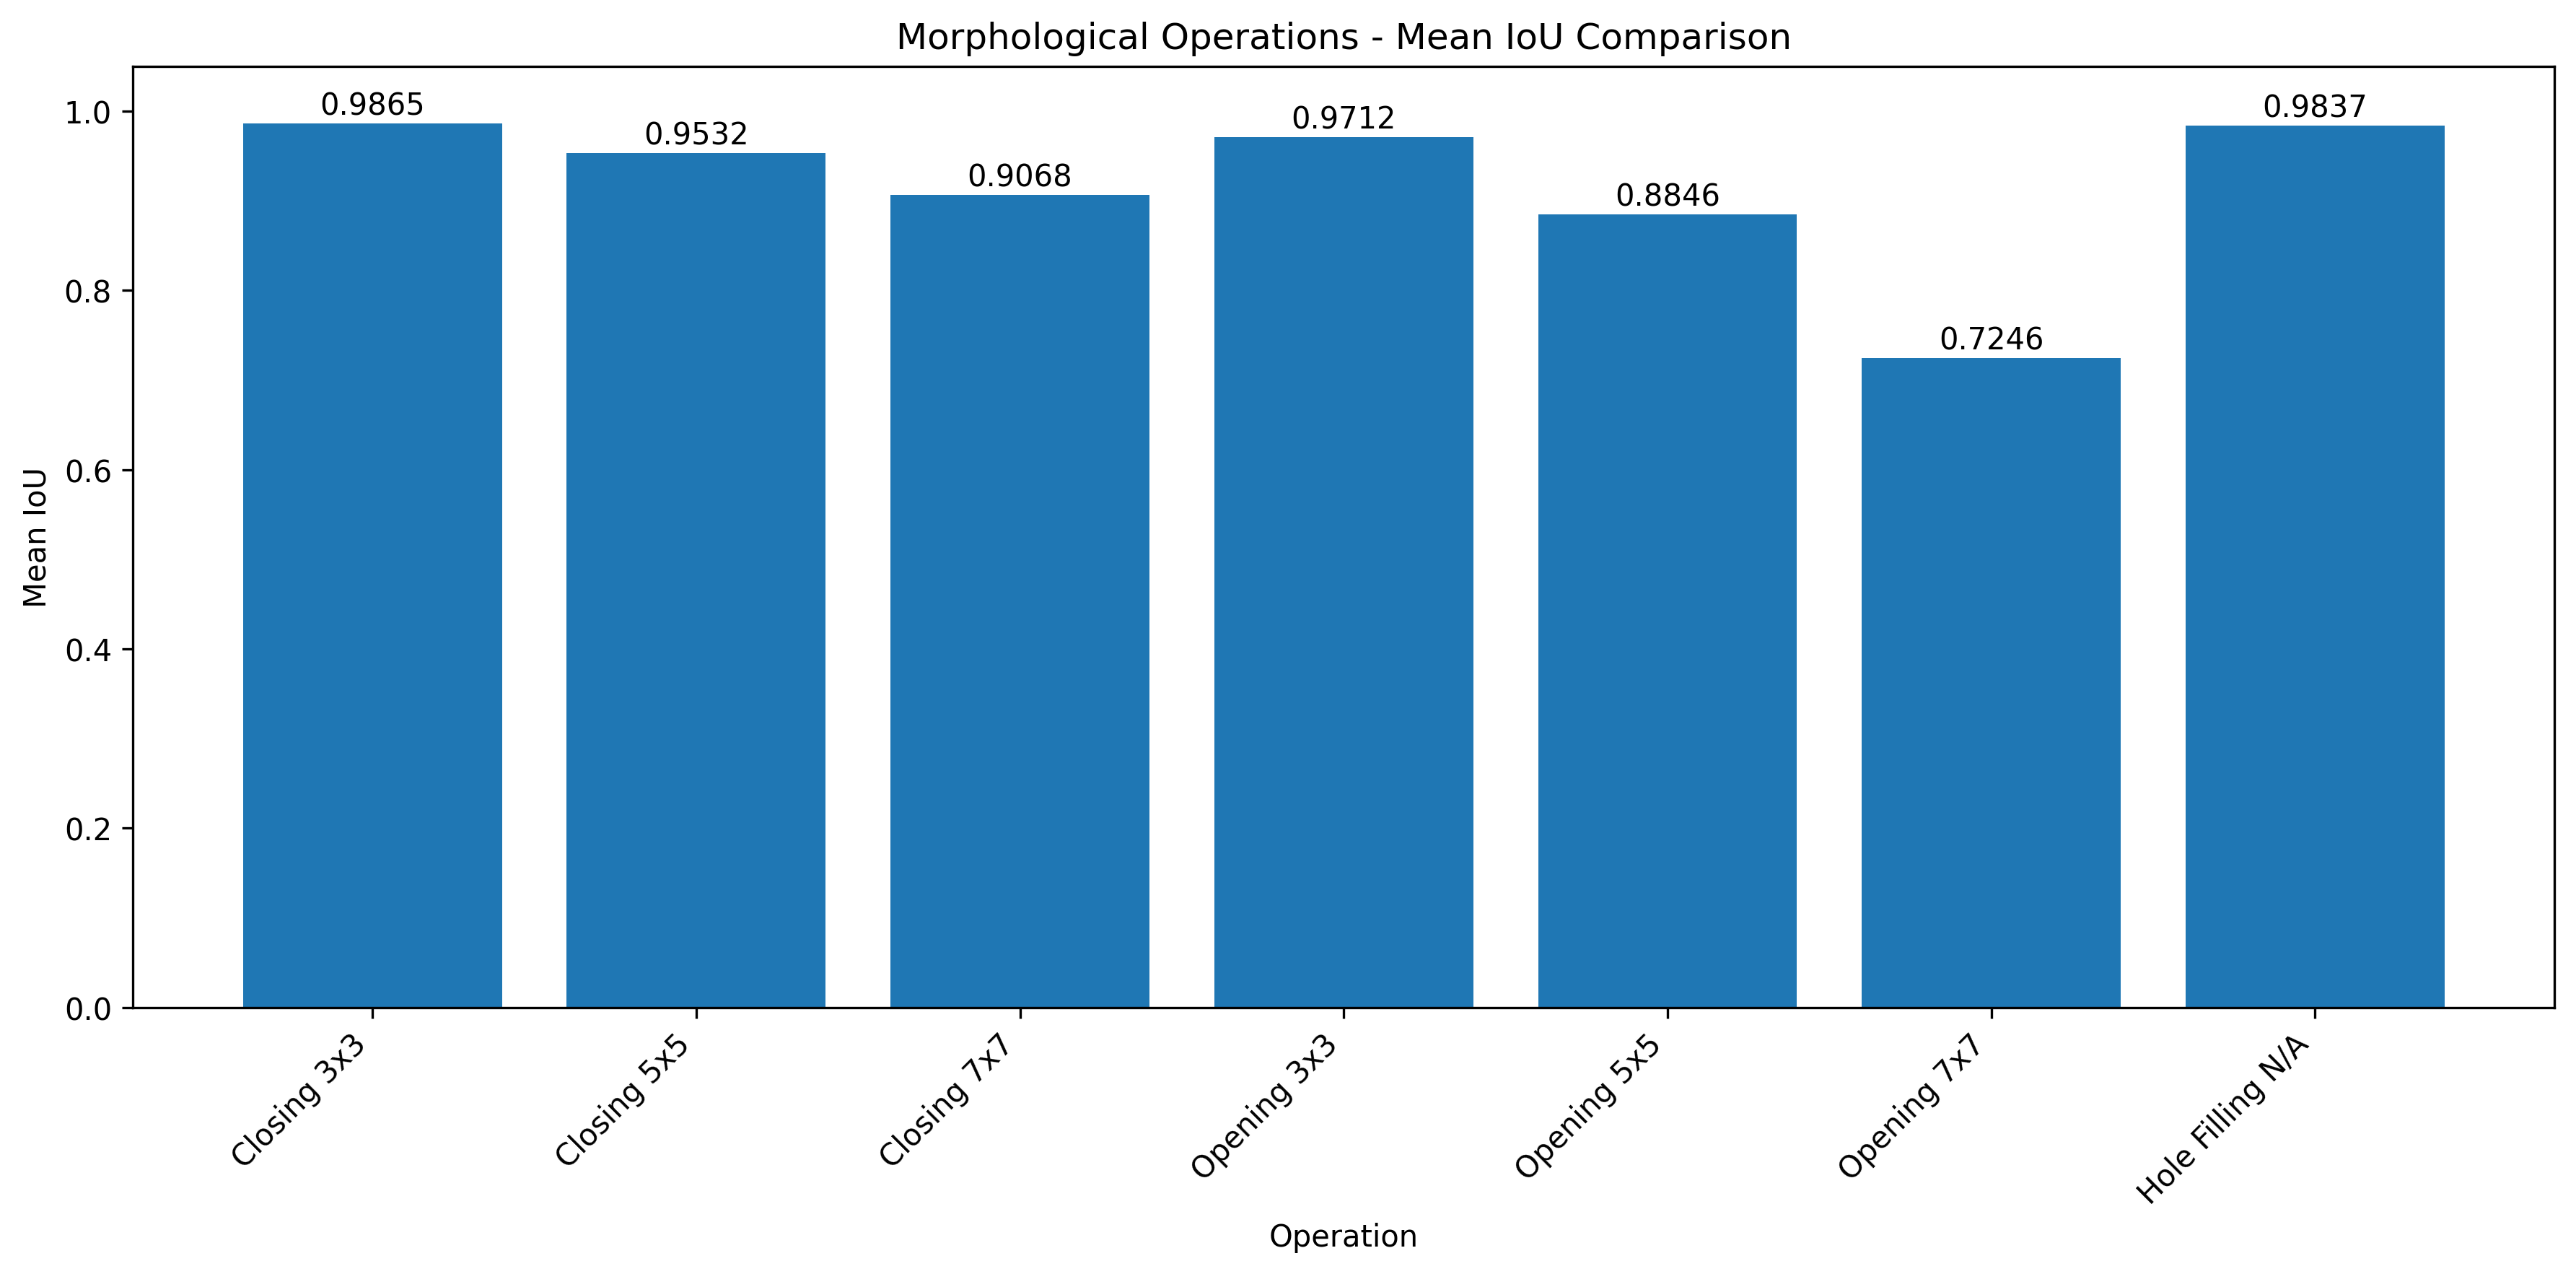


hole_filling_comparison.png


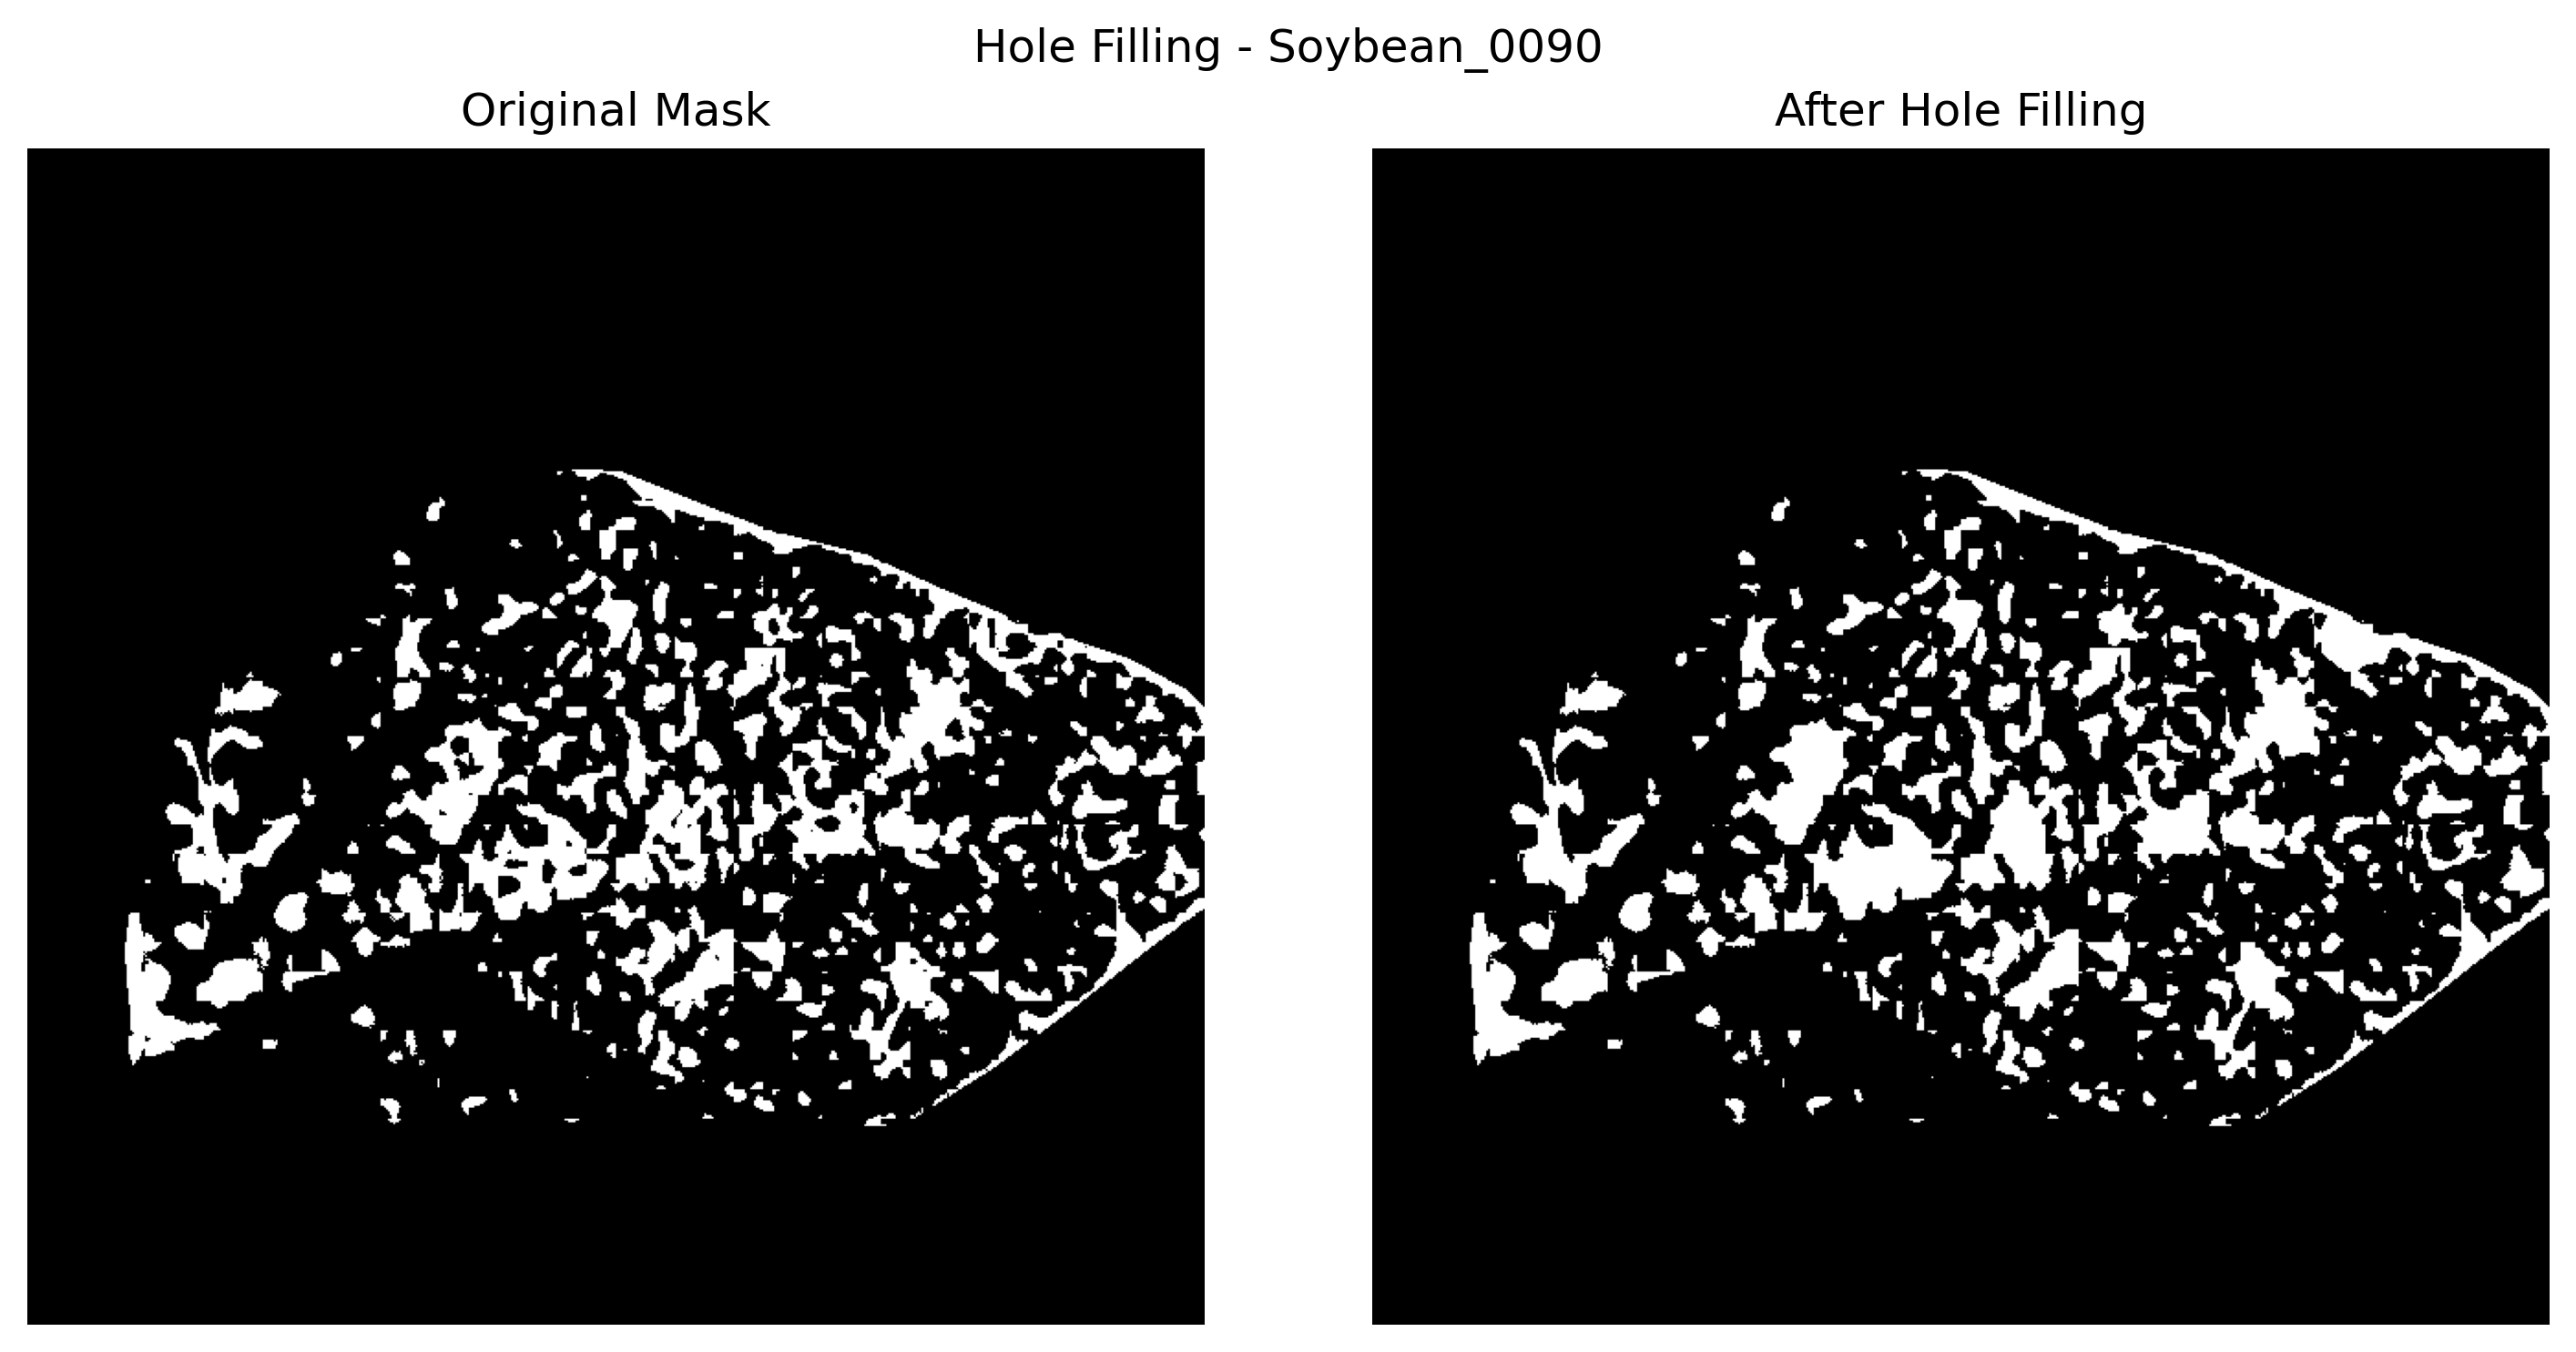

In [159]:
RESULT_IMAGE_NAMES = [
    "connected_components_analysis.png",
    "morphology_comparison.png",
    "morphology_iou_comparison.png",
    "hole_filling_comparison.png"
]

SEARCH_DIR = Path("/content")

for filename in RESULT_IMAGE_NAMES:
    matches = list(SEARCH_DIR.rglob(filename))

    if matches:
        image_path = matches[0]
        print(f"\n{filename}")
        display(Image(filename=str(image_path)))
    else:
        print(f"\nImage not found: {filename}")

## 10. Final Conclusion

The analysis covered dataset mask integrity, pixel distribution, connected components, morphological operations, hole filling, and segmentation baseline evaluation.

### Key Findings

- The dataset contains 240 images across three disease classes.
- No missing files were reported in the integrity check.
- Closing with a 3×3 kernel achieved the highest morphological preservation IoU of 0.986536.
- Hole filling achieved an IoU of 0.983655.
- Simple Otsu thresholding achieved a mean segmentation IoU of 0.3442.
- Soybean bacterial blight achieved the highest class-wise Otsu IoU of 0.6006.
- Segmentation performance varied across classes and individual images.

### Overall Conclusion

Morphological operations preserved the original mask structure to different degrees depending on the operation and kernel size. The baseline evaluation showed that simple thresholding performance varies across disease classes, indicating the need for more advanced segmentation approaches.

**Note:** Morphological preservation IoU and segmentation evaluation IoU represent different measurements and should not be interpreted as the same metric.